# Generative Models Workbook

**Day 8 · Human and Machine Perception**

How can machines generate visual worlds? This workbook goes through four families: autoencoders, variational autoencoders (VAEs), GANs and autoregressive models. Each section gives the idea, the math, and code to run in class.

**How to use it:** run the cells top to bottom. Sections 1 and 2 are written. Sections 3 and 4 are stubs.

*The autoencoder section is adapted from priyammaz/PyTorch-Adventures, "Intro to AutoEncoders" (MIT License). The code is rewritten. The MP4 analogy and the compact-latent argument follow the original.*

## The four families at a glance

| Family | Core idea | How you make a new image | Section |
|---|---|---|---|
| Autoencoder | Squeeze an image through a small code, then rebuild it | Decode a code. Random codes often give noise | 1 (written) |
| VAE | An autoencoder whose codes follow a known distribution | Decode a sample from N(0, I) | 2 (written) |
| GAN | A generator and a discriminator play a game | Feed random noise to the generator | 3 (stub) |
| Autoregressive | Predict each pixel from the pixels before it | Sample one pixel at a time | 4 (stub) |

## Setup

Needs `torch`, `torchvision` and `matplotlib`. MNIST downloads into `data/` the first time you run this.

In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("device:", device)

# MNIST digits resized from 28 x 28 to 32 x 32 (a power of 2 makes the conv shapes clean)
transform = transforms.Compose([transforms.Resize((32, 32)), transforms.ToTensor()])
train_set = datasets.MNIST("data", train=True, download=True, transform=transform)
test_set = datasets.MNIST("data", train=False, download=True, transform=transform)
print("train:", len(train_set), " test:", len(test_set), " image:", tuple(train_set[0][0].shape))

device: mps
train: 60000  test: 10000  image: (1, 32, 32)


### Shared helpers

`train` fits any model that returns `(code, reconstruction)`. It uses mean squared error between the reconstruction and the input. `encode_all` collects codes for a dataset. `plot_latents` and `decode_grid` are for 2-number codes.

In [2]:
def train(model, epochs=5, batch_size=128, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    history = []
    for epoch in range(epochs):
        model.train()
        for x, _ in loader:
            x = x.to(device)
            _, recon = model(x)
            loss = F.mse_loss(recon, x)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        history.append(evaluate(model))
        print(f"epoch {epoch + 1}: test MSE {history[-1]:.5f}")
    return history


@torch.no_grad()
def evaluate(model):
    model.eval()
    total, count = 0.0, 0
    for x, _ in DataLoader(test_set, batch_size=512):
        x = x.to(device)
        _, recon = model(x)
        total += F.mse_loss(recon, x, reduction="sum").item()
        count += x.numel()
    return total / count


@torch.no_grad()
def encode_all(model, dataset):
    model.eval()
    codes, labels = [], []
    for x, y in DataLoader(dataset, batch_size=512):
        z, _ = model(x.to(device))
        codes.append(z.flatten(1).cpu())
        labels.append(y)
    return torch.cat(codes).numpy(), torch.cat(labels).numpy()


def plot_latents(z, y, title):
    plt.figure(figsize=(6, 5))
    sc = plt.scatter(z[:, 0], z[:, 1], c=y, cmap="tab10", s=3, alpha=0.7)
    plt.colorbar(sc, label="digit")
    plt.title(title)
    plt.xlabel("code 1")
    plt.ylabel("code 2")
    plt.show()


@torch.no_grad()
def decode_grid(model, lo, hi, n=12):
    """Decode an n x n grid of 2-number codes spanning [lo, hi] on each axis."""
    xs = np.linspace(lo[0], hi[0], n)
    ys = np.linspace(lo[1], hi[1], n)[::-1]  # top row = largest second code
    pts = torch.tensor([[x, y] for y in ys for x in xs], dtype=torch.float32, device=device)
    imgs = model.decoder(pts).view(n, n, 32, 32).cpu().numpy()
    grid = np.block([[imgs[i, j] for j in range(n)] for i in range(n)])
    plt.figure(figsize=(7, 7))
    plt.imshow(grid, cmap="gray")
    plt.axis("off")
    plt.show()


@torch.no_grad()
def reconstruct(model, x):
    model.eval()
    recon = model(x.unsqueeze(0).to(device))[1]  # second output is the reconstruction for AEs and VAEs
    return recon.squeeze().cpu().numpy()

---
## 1. Autoencoders

### The idea

An MP4 video does not store every frame in full. It stores a few reference frames and only the pixels that change. Most real data is redundant in the same way. Nearby pixels agree, and digits share strokes. An autoencoder learns a compression like this on its own.

- The **encoder** $f$ maps an image to a short code $z$ (the bottleneck).
- The **decoder** $g$ maps the code back to an image.
- No labels are needed. The input is its own target.

The code must be smaller than the input. Otherwise the network can copy its input and learn nothing useful.

### The math

Let $x \in \mathbb{R}^{1024}$ be a 32 × 32 image, flattened. For a code of size $k$:

$$z = f_\phi(x) \in \mathbb{R}^{k}, \qquad \hat{x} = g_\theta(z) \in \mathbb{R}^{1024}$$

Train both networks together so the reconstruction matches the input:

$$\mathcal{L}(\theta, \phi) = \frac{1}{N} \sum_{i=1}^{N} \left\lVert x_i - g_\theta\big(f_\phi(x_i)\big) \right\rVert_2^2$$

The compression ratio is $1024 / k$. With $k = 2$ that is 512 to 1.

### 1.1 A nonlinear autoencoder with a 2-number code

Two hidden layers on each side, ReLU between layers, and a sigmoid at the output because pixels are in [0, 1]. The 2-number code lets us plot every test image as one point.

In [3]:
class MLPAutoEncoder(nn.Module):
    def __init__(self, bottleneck=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 32, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, bottleneck),
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck, 32), nn.ReLU(),
            nn.Linear(32, 64), nn.ReLU(),
            nn.Linear(64, 128), nn.ReLU(),
            nn.Linear(128, 32 * 32), nn.Sigmoid(),
        )

    def forward(self, x):
        z = self.encoder(x)
        recon = self.decoder(z).view(-1, 1, 32, 32)
        return z, recon


nonlinear_ae = MLPAutoEncoder(bottleneck=2)
nonlinear_hist = train(nonlinear_ae, epochs=5)

epoch 1: test MSE 0.04366


epoch 2: test MSE 0.04007


epoch 3: test MSE 0.03648


epoch 4: test MSE 0.03508


epoch 5: test MSE 0.03388


Plot the 2-number codes of the test set, coloured by digit. Digits that look alike should land near each other.

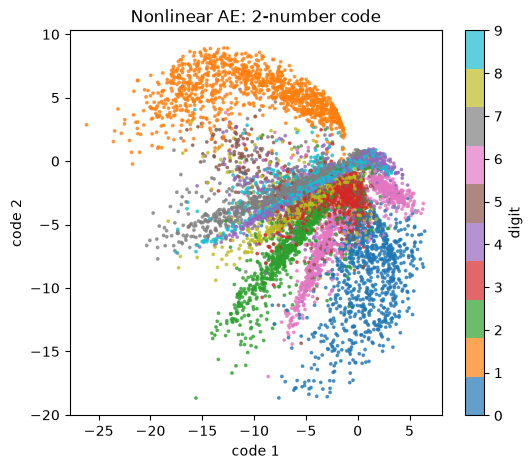

In [4]:
z_nl, y_test = encode_all(nonlinear_ae, test_set)
plot_latents(z_nl, y_test, "Nonlinear AE: 2-number code")

### 1.2 A linear autoencoder vs PCA

PCA finds the directions that carry the most variance. A linear autoencoder trained with squared error reaches a close answer. Its best solution spans the same subspace as the top principal components (Baldi and Hornik, 1989). The individual axes can rotate, so we compare the **reconstruction error**, not the axes.

PCA with $k$ components solves

$$\min_{P \in \mathbb{R}^{k \times d},\; PP^\top = I_k} \sum_{i} \left\lVert (x_i - \mu) - P^\top P (x_i - \mu) \right\rVert_2^2, \qquad \mu = \text{mean image}$$

Among all linear codes with 2 numbers, PCA has the lowest error. No linear autoencoder can beat it.

epoch 1: test MSE 0.05875


epoch 2: test MSE 0.05523


epoch 3: test MSE 0.05450


epoch 4: test MSE 0.05365


epoch 5: test MSE 0.05255


epoch 6: test MSE 0.05121


... (11 outputs left out)

epoch 18: test MSE 0.04566


epoch 19: test MSE 0.04570


epoch 20: test MSE 0.04569


PCA (2 numbers) reconstruction MSE:  0.04555
Linear AE (2 numbers) test MSE:      0.04569
PCA axes angle:             90.0 degrees
Linear AE directions angle: 88.75 degrees


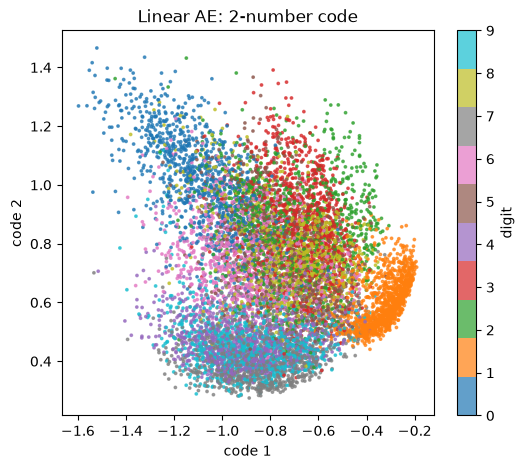

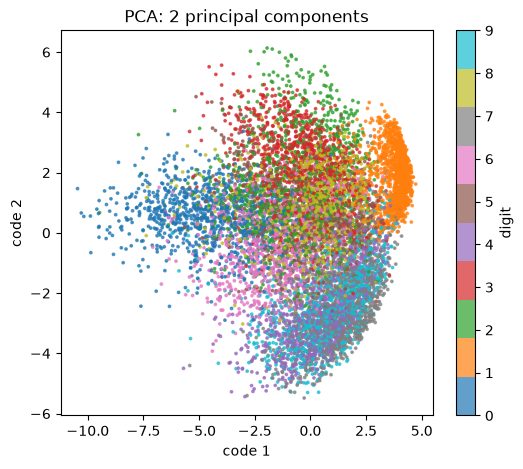

In [5]:
class LinearAutoEncoder(nn.Module):
    def __init__(self, bottleneck=2):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(32 * 32, bottleneck))
        self.decoder = nn.Sequential(nn.Linear(bottleneck, 32 * 32))

    def forward(self, x):
        z = self.encoder(x)
        recon = self.decoder(z).view(-1, 1, 32, 32)
        return z, recon


linear_ae = LinearAutoEncoder(bottleneck=2)
linear_hist = train(linear_ae, epochs=20)

# PCA on the same test images, computed with a singular value decomposition
X = torch.cat([x.flatten(1) for x, _ in DataLoader(test_set, batch_size=1000)]).numpy()
mu = X.mean(axis=0)
Xc = X - mu
_, _, Vt = np.linalg.svd(Xc, full_matrices=False)
P = Vt[:2]                              # top-2 principal directions, orthonormal rows
pca_mse = np.mean((Xc - Xc @ P.T @ P) ** 2)

print(f"PCA (2 numbers) reconstruction MSE:  {pca_mse:.5f}")
print(f"Linear AE (2 numbers) test MSE:      {linear_hist[-1]:.5f}")

# Angle between the encoder directions: PCA's two axes are exactly 90 degrees apart
W = linear_ae.encoder[1].weight.detach().cpu().numpy()   # shape (2, 1024)
w1, w2 = W[0] / np.linalg.norm(W[0]), W[1] / np.linalg.norm(W[1])
print("PCA axes angle:            ", round(float(np.degrees(np.arccos(np.clip(P[0] @ P[1], -1, 1)))), 2), "degrees")
print("Linear AE directions angle:", round(float(np.degrees(np.arccos(np.clip(w1 @ w2, -1, 1)))), 2), "degrees")

z_lin, _ = encode_all(linear_ae, test_set)
plot_latents(z_lin, y_test, "Linear AE: 2-number code")
plot_latents((Xc @ P.T), y_test, "PCA: 2 principal components")

The two plots look alike. Each one is the other with a linear change of axes and a scale. The errors are nearly identical, and the linear autoencoder got there with gradient descent instead of an eigen-decomposition.

The nonlinear autoencoder with the same 2 numbers reaches a lower error than PCA. Nonlinear layers let the code bend around the shape of the digits. Gradient descent is what makes that possible, because it does not need the linear algebra to have a closed form.

### 1.3 A convolutional autoencoder

An image is a grid, so keep the grid. Convolutions shrink height and width and grow the channels. Transposed convolutions reverse each step. The code is a 4 × 4 × 4 block: 64 numbers instead of 2. Compression is weaker, so reconstructions should be better.

| Stage | Shape (C × H × W) | Numbers |
|---|---|---|
| Input | 1 × 32 × 32 | 1024 |
| Conv, stride 2 | 8 × 16 × 16 | 2048 |
| Conv, stride 2 | 16 × 8 × 8 | 1024 |
| Code | 4 × 4 × 4 | 64 |

The output size of a transposed convolution is $(H_{in} - 1) \cdot 2 - 2 \cdot 1 + 3 + 1 = 2 H_{in}$, so 4 → 8 → 16 → 32.

In [6]:
class ConvAutoEncoder(nn.Module):
    def __init__(self, channels=4):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, stride=2, padding=1, bias=False), nn.BatchNorm2d(8), nn.ReLU(),
            nn.Conv2d(8, 16, kernel_size=3, stride=2, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, channels, kernel_size=3, stride=2, padding=1),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(channels, 16, kernel_size=3, stride=2, padding=1, output_padding=1, bias=False),
            nn.BatchNorm2d(16), nn.ReLU(),
            nn.ConvTranspose2d(16, 8, kernel_size=3, stride=2, padding=1, output_padding=1, bias=False),
            nn.BatchNorm2d(8), nn.ReLU(),
            nn.ConvTranspose2d(8, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        z = self.encoder(x)
        return z, self.decoder(z)


# Check the shapes before training
x0, _ = train_set[0]
z0, r0 = ConvAutoEncoder()(x0.unsqueeze(0))
print("code shape:", tuple(z0.shape), "->", z0.numel(), "numbers")
print("output shape:", tuple(r0.shape))

conv_ae = ConvAutoEncoder(channels=4)
conv_hist = train(conv_ae, epochs=5)

code shape: (1, 4, 4, 4) -> 64 numbers
output shape: (1, 1, 32, 32)


epoch 1: test MSE 0.02836


epoch 2: test MSE 0.00773


epoch 3: test MSE 0.00598


epoch 4: test MSE 0.00537


epoch 5: test MSE 0.00512


### 1.4 Compare the reconstructions

Each column is one test digit. The top row is the input. The middle row is the 2-number nonlinear autoencoder. The bottom row is the 64-number convolutional autoencoder.

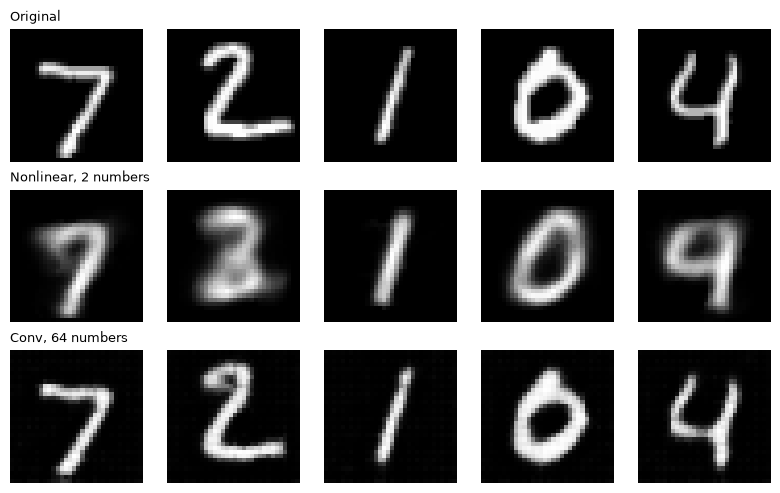

test MSE, nonlinear 2 numbers: 0.03388
test MSE, conv 64 numbers:     0.00512


In [7]:
fig, axes = plt.subplots(3, 5, figsize=(8, 5))
row_titles = ["Original", "Nonlinear, 2 numbers", "Conv, 64 numbers"]
for col in range(5):
    x, _ = test_set[col]
    rows = [x.squeeze().numpy(), reconstruct(nonlinear_ae, x), reconstruct(conv_ae, x)]
    for row, img in enumerate(rows):
        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(row_titles[row], loc="left", fontsize=9)
plt.tight_layout()
plt.show()

print(f"test MSE, nonlinear 2 numbers: {nonlinear_hist[-1]:.5f}")
print(f"test MSE, conv 64 numbers:     {conv_hist[-1]:.5f}")

With 2 numbers, the reconstructions are blurry, and the shapes drift. The 4 comes back as a 9. With 64 numbers, the strokes come back sharp. Same loss, same training. Only the size of the code changed.

### 1.5 Can we generate from the code?

The decoder takes a code and returns an image, so we can feed it codes we make up. Two questions come first:

1. Where do the real codes live? Check their mean and spread.
2. What does the decoder make from codes in between?

code mean: [-4.   -2.69]
code std:  [4.85 4.22]


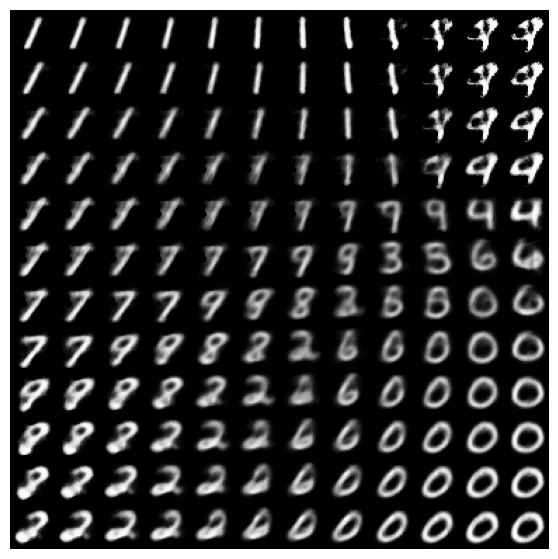

In [8]:
print("code mean:", np.round(z_nl.mean(axis=0), 2))
print("code std: ", np.round(z_nl.std(axis=0), 2))

# Decode a grid spanning the range where most real codes fall
lo = np.percentile(z_nl, 1, axis=0)
hi = np.percentile(z_nl, 99, axis=0)
decode_grid(nonlinear_ae, lo, hi)

Look at the grid. Some paths morph smoothly from one digit to another, such as 7 to 9 to 4. Many codes between the clusters decode into blurry blends or shapes that are not digits. The loss never asked the autoencoder to make the space between clusters sensible, so the space is not compact.

Now sample from the standard normal, N(0, I), the usual way to draw a random input to a generator. The real codes have a mean around (-4, -2.7) and a spread of about 4 to 5. N(0, I) is centered at the origin with spread 1, so it lands somewhere the encoder never placed real digits.

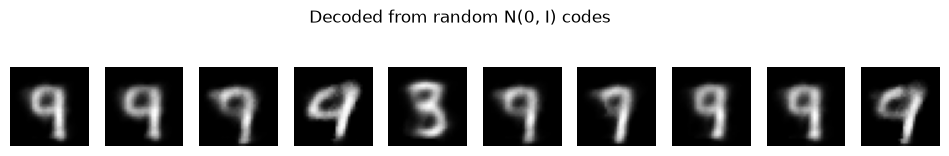

In [9]:
rng = np.random.default_rng(0)
random_codes = rng.standard_normal((10, 2))

with torch.no_grad():
    samples = nonlinear_ae.decoder(torch.tensor(random_codes, dtype=torch.float32, device=device))
samples = samples.view(-1, 32, 32).cpu().numpy()

fig, axes = plt.subplots(1, 10, figsize=(12, 2))
for ax, img in zip(axes, samples):
    ax.imshow(img, cmap="gray")
    ax.axis("off")
plt.suptitle("Decoded from random N(0, I) codes")
plt.show()

Many look like digits, but most are the same 9-like blend, and the ten samples do not cover the ten digits. Nothing in the loss told the model what the region near N(0, I) should look like. A plain autoencoder can't be sampled reliably.

**Next:** a variational autoencoder changes the loss so the codes must follow N(0, I). Then sampling works by design (Section 2).

### 1.6 Check yourself

1. Why does the loss not need labels?
2. What would go wrong if the code were bigger than the input, say $k = 2048$?
3. Why is PCA's error a lower bound for any linear autoencoder with 2 numbers?

### 1.7 Exercises

1. Set the nonlinear bottleneck to 8, then 32, retraining each time. Plot test MSE against $k$. Where does the curve flatten?
2. Remove the sigmoid from the nonlinear decoder. Does training change? Why might the sigmoid help?
3. **Denoising.** Add Gaussian noise to the input during training, but compute the loss against the clean image. What does the model learn to remove?

---
## 2. Variational autoencoders

*Adapted in part from priyammaz/PyTorch-Adventures, "Variational AutoEncoders" (MIT License). The derivation is rewritten, and the code is our own.*

### Why generation needs more than an autoencoder

A **discriminative** model learns $P(y \mid x)$: given an image, predict its label. A **generative** model learns the data distribution $P(x)$ itself. If we can sample from $P(x)$, we can make new data.

Section 1 showed the problem. The autoencoder's codes sit in a region we never controlled, so a random draw from N(0, I) decodes to junk. A VAE fixes this by making the codes follow N(0, I) on purpose.

### The math: from Bayes to the ELBO

A latent-variable model says an image $x$ comes from a hidden code $z$ with a simple prior $p(z) = \mathcal{N}(0, I)$, and a decoder $p_\theta(x \mid z)$:

$$p_\theta(x) = \int p_\theta(x \mid z)\, p(z)\, dz$$

This integral is intractable for a neural decoder. The posterior $p_\theta(z \mid x)$ is intractable too, since it depends on that integral. So we learn an approximate posterior, the **encoder** $q_\phi(z \mid x)$, and maximize a lower bound on $\log p_\theta(x)$, the **ELBO**:

$$\log p_\theta(x) \;\ge\; \underbrace{\mathbb{E}_{q_\phi(z\mid x)}\big[\log p_\theta(x \mid z)\big]}_{\text{reconstruction}} \;-\; \underbrace{D_{KL}\big(q_\phi(z \mid x) \,\|\, p(z)\big)}_{\text{KL to the prior}}$$

Minimizing the loss $\mathcal{L} = -\text{ELBO}$ does two jobs at once:

- **Reconstruction** pulls codes apart, so each image can be recovered.
- **KL** pulls every code's distribution toward N(0, I), so the codes overlap and fill the space.

The encoder predicts a Gaussian for each image, $q_\phi(z \mid x) = \mathcal{N}(\mu_\phi(x), \operatorname{diag}\sigma_\phi^2(x))$. For a diagonal Gaussian against N(0, I), the KL has a closed form:

$$D_{KL} = -\frac{1}{2} \sum_{j} \left(1 + \log \sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

With a Gaussian decoder of fixed variance, $-\log p_\theta(x \mid z)$ is a constant times the squared error, so the reconstruction term is a sum of squared pixel errors. We add a weight $\beta$ on the KL, which lets us see what happens when the latent space is pushed harder:

$$\mathcal{L}_\beta = \underbrace{\sum_{\text{pixels}} (x - \hat{x})^2}_{\text{reconstruction}} + \beta \cdot \underbrace{\left(-\frac{1}{2}\sum_j \left(1 + \log \sigma_j^2 - \mu_j^2 - \sigma_j^2\right)\right)}_{\text{KL}}$$

Keep the scale in mind. A per-pixel mean would make the reconstruction term tiny next to the KL, so we sum over pixels for each image. Then $\beta = 1$ is a reasonable default.

### The reparameterization trick

Sampling $z \sim \mathcal{N}(\mu, \sigma^2)$ blocks gradients from reaching $\mu$ and $\sigma$. The fix is to move the randomness into a fixed noise $\varepsilon \sim \mathcal{N}(0, I)$:

$$z = \mu + \sigma \odot \varepsilon$$

Now $z$ is a differentiable function of $\mu$ and $\sigma$, and the noise is an input we do not train. The network predicts $\log \sigma^2$ rather than $\sigma$, for numerical stability. Then $\sigma = \exp\!\big(\tfrac{1}{2}\log \sigma^2\big)$.

Run the cell below to see the difference.

In [10]:
# A toy check: does gradient reach w through the sample?
w = torch.tensor(2.0, requires_grad=True)
mu = 8.0 * w * 3.0          # mean depends on w
sigma = torch.tensor(1.0)

# Plain sampling: the sample has no link back to w
z_plain = torch.distributions.Normal(mu, sigma).sample()
print("plain sample requires grad:", z_plain.requires_grad)

# Reparameterized sample: the randomness is an input, so the gradient flows
z_reparam = mu + sigma * torch.randn(())
z_reparam.backward()
print("gradient of the reparameterized sample w.r.t. w:", w.grad.item())

plain sample requires grad: False
gradient of the reparameterized sample w.r.t. w: 24.0


### 2.1 The loss in code

`vae_loss` returns the total loss, the reconstruction part and the KL part, so you can watch the balance.

In [11]:
def reparameterize(mu, logvar):
    std = torch.exp(0.5 * logvar)
    eps = torch.randn_like(std)
    return mu + std * eps


def vae_loss(x, recon, mu, logvar, kl_weight=1.0):
    # Sum of squared errors over the pixels of each image, averaged over the batch
    recon_loss = F.mse_loss(recon, x, reduction="none").flatten(1).sum(dim=1).mean()
    # Closed-form KL per image, averaged over the batch
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1).mean()
    return recon_loss + kl_weight * kl, recon_loss, kl

### 2.2 A linear VAE with a 2-number code

The same MLP as Section 1, but the encoder ends in two heads: one for $\mu$ and one for $\log \sigma^2$. The decoder is unchanged.

In [12]:
class LinearVAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 32, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 32),
        )
        self.fc_mu = nn.Linear(32, latent_dim)
        self.fc_logvar = nn.Linear(32, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32), nn.ReLU(),
            nn.Linear(32, 64), nn.ReLU(),
            nn.Linear(64, 128), nn.ReLU(),
            nn.Linear(128, 32 * 32), nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = reparameterize(mu, logvar)
        recon = self.decoder(z).view(-1, 1, 32, 32)
        return z, recon, mu, logvar


@torch.no_grad()
def evaluate_vae(model, kl_weight=1.0):
    model.eval()
    rec_total, kl_total, n = 0.0, 0.0, 0
    for x, _ in DataLoader(test_set, batch_size=512):
        x = x.to(device)
        _, recon, mu, logvar = model(x)
        _, rec, kl = vae_loss(x, recon, mu, logvar, kl_weight)
        rec_total += rec.item() * len(x)
        kl_total += kl.item() * len(x)
        n += len(x)
    return rec_total / n, kl_total / n


def train_vae(model, kl_weight=1.0, epochs=5, batch_size=128, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    for epoch in range(epochs):
        model.train()
        for x, _ in loader:
            x = x.to(device)
            _, recon, mu, logvar = model(x)
            loss, _, _ = vae_loss(x, recon, mu, logvar, kl_weight)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        rec, kl = evaluate_vae(model, kl_weight)
        print(f"epoch {epoch + 1}: test reconstruction {rec:.1f}, KL {kl:.2f}")
    return model


@torch.no_grad()
def encode_mu(model, dataset):
    model.eval()
    mus, labels = [], []
    for x, y in DataLoader(dataset, batch_size=512):
        mu, _ = model.encode(x.to(device))
        mus.append(mu.cpu())
        labels.append(y)
    return torch.cat(mus).numpy(), torch.cat(labels).numpy()


# Two linear VAEs: a normal KL weight, and a heavy one to see what over-regularizing does
print("KL weight 1")
vae_b1 = train_vae(LinearVAE(latent_dim=2), kl_weight=1.0, epochs=5)
print("KL weight 100")
vae_b100 = train_vae(LinearVAE(latent_dim=2), kl_weight=100.0, epochs=5)

KL weight 1


epoch 1: test reconstruction 49.9, KL 1.73


epoch 2: test reconstruction 41.8, KL 3.48


epoch 3: test reconstruction 39.5, KL 3.84


epoch 4: test reconstruction 37.9, KL 3.99


epoch 5: test reconstruction 36.9, KL 4.26
KL weight 100


epoch 1: test reconstruction 58.5, KL 0.00


epoch 2: test reconstruction 58.3, KL 0.00


epoch 3: test reconstruction 58.2, KL 0.00


epoch 4: test reconstruction 58.2, KL 0.00


epoch 5: test reconstruction 58.2, KL 0.00


### 2.3 Compare the latent spaces

Plot the mean $\mu$ of each encoder for the test set. The autoencoder from Section 1 is on the left for comparison. With $\beta = 1$, the codes spread into a blob around the middle, with each class in its own part of it. With $\beta = 100$, the KL term wins. The codes shrink to a tiny cluster at the origin, the KL goes to zero, and the encoder has stopped using the image.

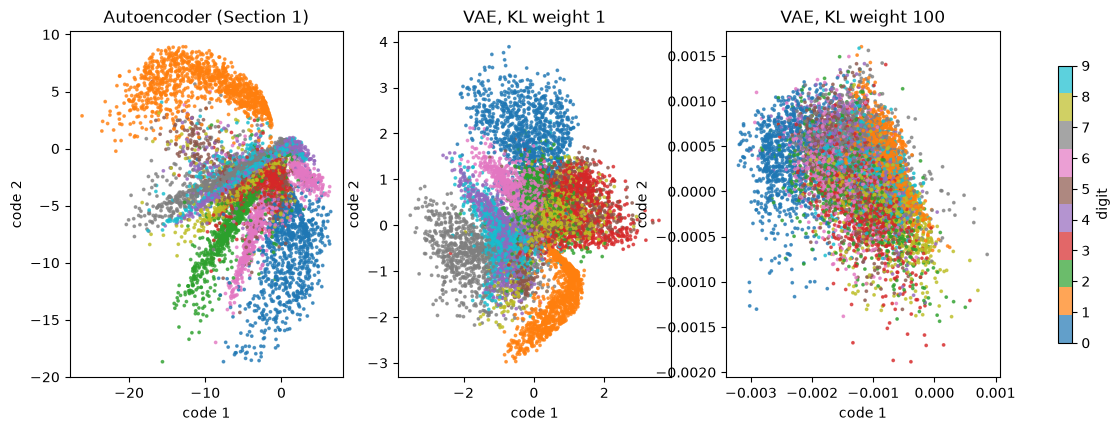

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
panels = [
    (z_nl, "Autoencoder (Section 1)"),
    (encode_mu(vae_b1, test_set)[0], "VAE, KL weight 1"),
    (encode_mu(vae_b100, test_set)[0], "VAE, KL weight 100"),
]
for ax, (z, title) in zip(axes, panels):
    sc = ax.scatter(z[:, 0], z[:, 1], c=y_test, cmap="tab10", s=3, alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel("code 1")
    ax.set_ylabel("code 2")
fig.colorbar(sc, ax=axes, label="digit", shrink=0.8)
plt.show()

### 2.4 Walk the latent space

Each cell is a decoded point on a grid over $[-2, 2]$ for both code values. Moving across the grid should change one digit smoothly into another. Compare with the grid from Section 1.5.

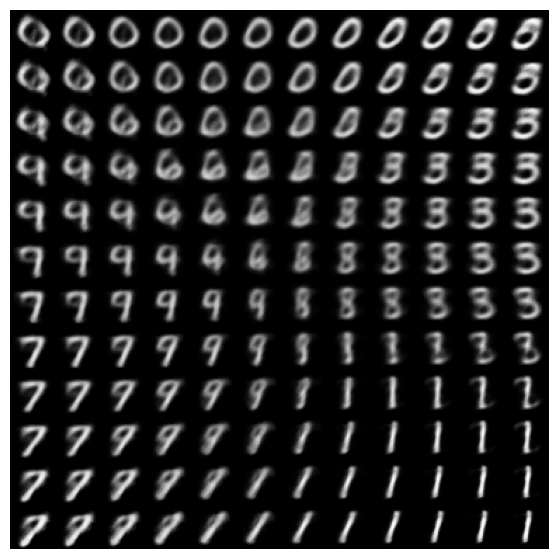

In [14]:
decode_grid(vae_b1, lo=(-2, -2), hi=(2, 2))

### 2.5 Generate from the prior

This is the payoff. Draw codes from N(0, I) and decode them. Compare with the row from Section 1.5, which was mostly one blended 9.

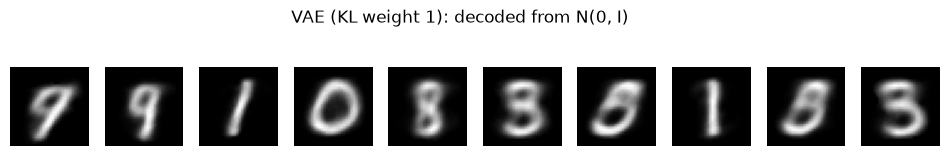

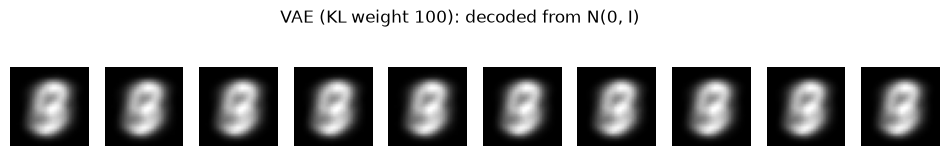

In [15]:
@torch.no_grad()
def sample_from_prior(model, shape, n=10, seed=0):
    g = torch.Generator().manual_seed(seed)
    z = torch.randn((n,) + shape, generator=g).to(device)
    return model.decoder(z).view(n, 32, 32).cpu().numpy()


def show_row(imgs, title):
    fig, axes = plt.subplots(1, len(imgs), figsize=(12, 2))
    for ax, img in zip(axes, imgs):
        ax.imshow(img, cmap="gray")
        ax.axis("off")
    plt.suptitle(title)
    plt.show()


show_row(sample_from_prior(vae_b1, (2,)), "VAE (KL weight 1): decoded from N(0, I)")
show_row(sample_from_prior(vae_b100, (2,)), "VAE (KL weight 100): decoded from N(0, I)")

With $\beta = 1$, the samples cover several digit classes, though many are blurry. With $\beta = 100$, every sample decodes to the same blurry blend. The KL is zero, so the decoder gets no information from the code. This is called posterior collapse. The loss traded all reconstruction for a perfect match to the prior.

### 2.6 A convolutional VAE

Same idea with a 4 × 4 × 4 latent cube. Two convolutions take the place of $\mu$ and $\log \sigma^2$. The encoder ends without a ReLU, so $\mu$ can take negative values.

In [16]:
class ConvVAE(nn.Module):
    def __init__(self, channels=4):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, stride=2, padding=1, bias=False), nn.BatchNorm2d(8), nn.ReLU(),
            nn.Conv2d(8, 16, kernel_size=3, stride=2, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, channels, kernel_size=3, stride=2, padding=1),
        )
        self.conv_mu = nn.Conv2d(channels, channels, kernel_size=3, stride=1, padding="same")
        self.conv_logvar = nn.Conv2d(channels, channels, kernel_size=3, stride=1, padding="same")
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(channels, 16, kernel_size=3, stride=2, padding=1, output_padding=1, bias=False),
            nn.BatchNorm2d(16), nn.ReLU(),
            nn.ConvTranspose2d(16, 8, kernel_size=3, stride=2, padding=1, output_padding=1, bias=False),
            nn.BatchNorm2d(8), nn.ReLU(),
            nn.ConvTranspose2d(8, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.conv_mu(h), self.conv_logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = reparameterize(mu, logvar)
        recon = self.decoder(z)
        return z, recon, mu, logvar


conv_vae = ConvVAE(channels=4)
conv_vae = train_vae(conv_vae, kl_weight=1.0, epochs=5)

epoch 1: test reconstruction 14.8, KL 4.94


epoch 2: test reconstruction 9.0, KL 5.11


epoch 3: test reconstruction 7.8, KL 5.03


epoch 4: test reconstruction 7.3, KL 5.04


epoch 5: test reconstruction 7.0, KL 5.08


### 2.7 Reconstructions and samples: the blur

Top row: the input. Then the Section 1 convolutional autoencoder, then the convolutional VAE. The VAE reconstructions are softer, because the KL term keeps the code from carrying every detail. Its test reconstruction error is also higher. The strip below the grid samples the convolutional VAE from N(0, I). Those samples are weak here: most are faint fragments, not digits. Five epochs is short for a 64-number code, so treat this as something to discuss, not a finished model.

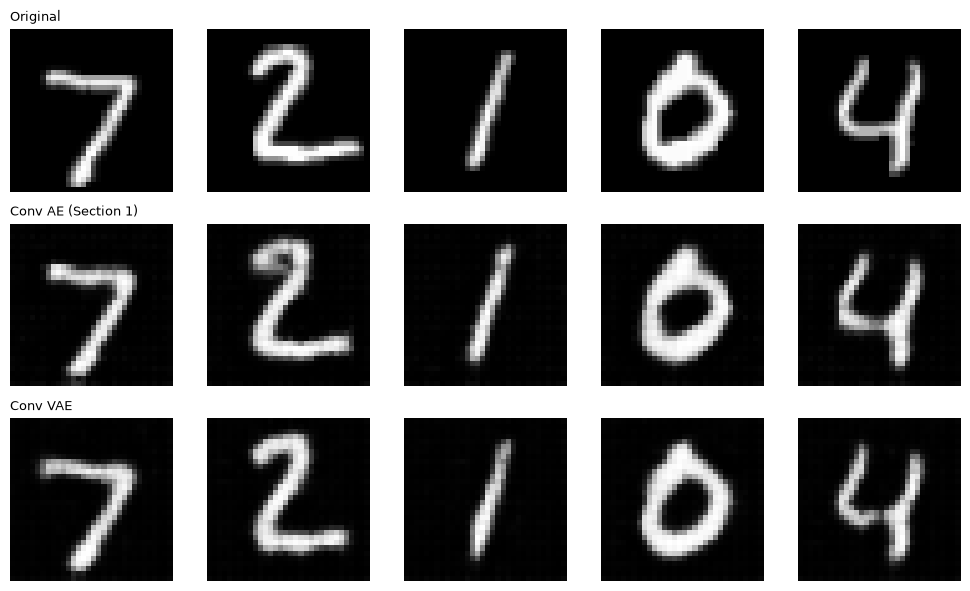

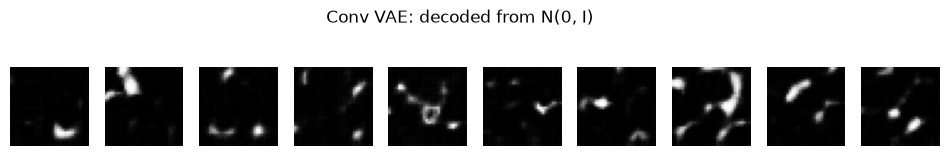

In [17]:
fig, axes = plt.subplots(3, 5, figsize=(10, 6))
row_titles = ["Original", "Conv AE (Section 1)", "Conv VAE"]
for col in range(5):
    x, _ = test_set[col]
    rows = [x.squeeze().numpy(), reconstruct(conv_ae, x), reconstruct(conv_vae, x)]
    for row, img in enumerate(rows):
        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(row_titles[row], loc="left", fontsize=9)
plt.tight_layout()
plt.show()

show_row(sample_from_prior(conv_vae, (4, 4, 4)), "Conv VAE: decoded from N(0, I)")

### 2.8 Check yourself

1. Why does the KL term need to be closed-form, rather than estimated by sampling every time?
2. In the reparameterization check above, why does the plain sample have no gradient to $w$?
3. What happens to reconstructions if you set $\beta = 0$? What about $\beta = 1000$?

### 2.9 Exercises

1. Train the linear VAE with $\beta$ at 0.1, 1, 10 and 100. Make a plot of test reconstruction against test KL. Each point is one model.
2. Replace the mean-squared error in `vae_loss` with binary cross-entropy. What changes about the reconstructions?
3. Look ahead. A VAE's codes are continuous, so classes can blend. VQ-VAE replaces the code with a nearest entry in a learned codebook of discrete vectors. Read one paragraph on it and write down what you expect would change in the walk across the grid.

---
## 3. GANs (to write)

Next: generator vs discriminator, the minimax loss, and a small DCGAN-style model on MNIST.

---
## 4. Autoregressive models (to write)

Next: factor $p(x)$ as a product of conditionals over pixels, a masked convolution or small transformer, and sampling one pixel at a time.